##
assignment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("hour.csv")

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
df.shape

(17379, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [5]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [6]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


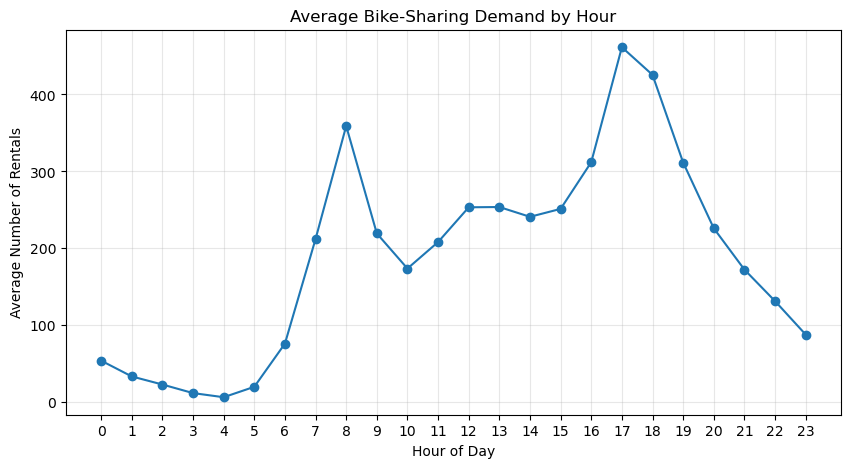

In [8]:

hourly_demand = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.title("Average Bike-Sharing Demand by Hour")

plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.savefig(
    "images/demand_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


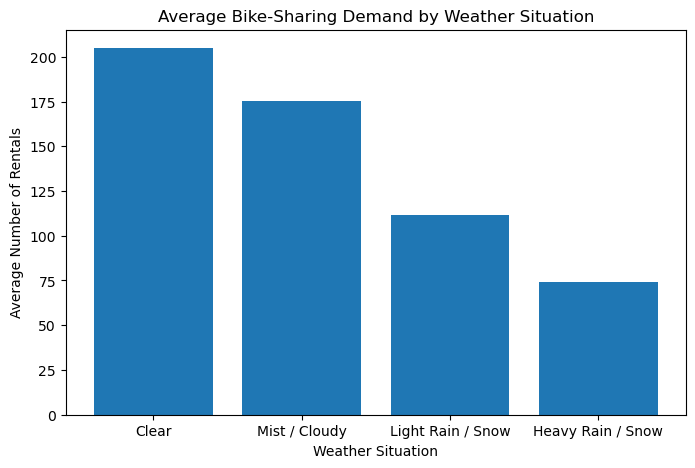

In [9]:

weather_demand = df.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(8, 5))
plt.bar(weather_demand.index, weather_demand.values)

plt.xlabel("Weather Situation")
plt.ylabel("Average Number of Rentals")
plt.title("Average Bike-Sharing Demand by Weather Situation")

plt.xticks(
    [1, 2, 3, 4],
    ["Clear", "Mist / Cloudy", "Light Rain / Snow", "Heavy Rain / Snow"]
)

plt.savefig(
    "images/demand_by_weather.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


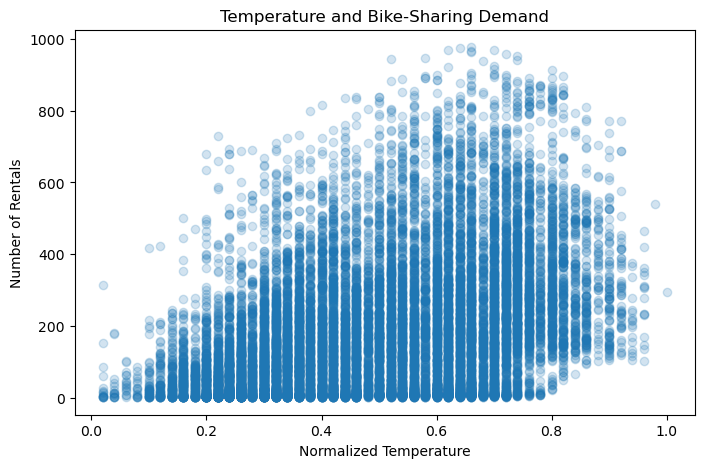

In [10]:

plt.figure(figsize=(8, 5))

plt.scatter(df["temp"], df["cnt"], alpha=0.2)

plt.xlabel("Normalized Temperature")
plt.ylabel("Number of Rentals")
plt.title("Temperature and Bike-Sharing Demand")

plt.savefig(
    "images/temperature_vs_demand.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [11]:
## Dataset Overview

#The dataset contains 17,379 hourly observations of bike-sharing activity in Washington, D.C. The dataset includes time-related variables such as year, month, hour, weekday, and working day, as well as weather-related variables including weather situation, temperature, humidity, and wind speed.

#There are no missing values in the dataset. The variable `cnt` represents the total number of bike rentals and is used as the main measure of bike-sharing demand.

In [12]:
## Visualization and Research Question

#The visualizations are designed to investigate how weather and time-related factors are associated with bike-sharing demand in Washington, D.C. The hourly demand chart shows how the average number of rentals changes throughout the day, allowing different periods to be compared. The weather-situation chart compares average rental demand under different weather conditions, while the temperature scatter plot provides a visual view of the relationship between temperature and rental demand.

#Together, these visualizations provide a direct way to explore the research question by comparing bike-sharing demand across different time periods and weather conditions. The patterns observed in the charts can be used as evidence when interpreting how these factors are associated with bike-sharing usage.